In [1]:
import pandas as pd
from utils import merge_csv_files_in_directory, standardize_labels
from IPython.display import display, HTML

df = merge_csv_files_in_directory()

#remove duplicates
df = df.drop_duplicates(keep='first')

df.drop("pr_title",inplace = True,axis=1)
df.drop("class_names",inplace = True,axis=1)
df.drop("commit_sha",inplace = True,axis=1)
df.drop("commit_message",inplace = True,axis=1)
df.drop("file_path",inplace = True,axis=1)
df.drop("additions",inplace = True,axis=1)
df.drop("deletions",inplace = True,axis=1)
df.drop("file_name",inplace = True,axis=1)
df.drop("full_repo_name",inplace = True,axis=1)

#df.drop("content_before",inplace = True,axis=1)
#df.drop("content_after",inplace = True,axis=1)

df.drop("patch",inplace = True,axis=1)

df.drop("created_at",inplace = True,axis=1)
df.drop("closed_at",inplace = True,axis=1)
df.drop("status",inplace = True,axis=1)

### Limit df size for testing purposes ###
# Sample 10 rows of each label type
label_enh = df[df['labels'] == 'enhancement']
label_bug = df[df['labels'] == 'bug']
sampled_enh = label_enh.sample(n=200, random_state=1)
sampled_bug = label_bug.sample(n=200, random_state=1)
df = pd.concat([sampled_enh, sampled_bug])

# Standardize labels
labels = ['bug', 'enhancement', 'performance', 'refactor', 'clean']
df = standardize_labels(df, labels)
resulting_label_count = df['labels'].nunique()

# Display DataFrame with a scrollable table
#display(HTML(df.to_html(max_rows=None, max_cols=None)))

# Count the occurrences of each unique value in the 'lables' column
label_counts = df['labels'].value_counts()
print(label_counts)

df

Files have been merged and saved as merged.csv
labels
enhancement    200
bug            200
Name: count, dtype: int64


,labels,content_before,content_after
641,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
428,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
268,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
442,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
255,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
...,...,...,...
247,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
146,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
86,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
98,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...


In [2]:
from transformers import AutoTokenizer, AutoModel
import torch

tokenizer = AutoTokenizer.from_pretrained("microsoft/codebert-base")
model = AutoModel.from_pretrained("microsoft/codebert-base")

/opt/miniconda3/envs/code1001/lib/python3.11/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


In [3]:

# Tokenizing using subtracting full code before and after embeddings

def tokenize_code(batch):
    # Extracting the content before and after as lists of strings
    content_before = [item['content_before'] for item in batch]
    content_after = [item['content_after'] for item in batch]

    # Tokenize the before and after code snippets
    tokens_before = tokenizer(content_before, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
    tokens_after = tokenizer(content_after, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
    
    # Get the embeddings for both tokenized sequences
    with torch.no_grad():
        embeddings_before = model(**tokens_before).last_hidden_state
        embeddings_after = model(**tokens_after).last_hidden_state
    
    # Subtract the embeddings
    subtracted_embeddings = embeddings_after - embeddings_before
    
    # Average the subtracted embeddings across the token dimension
    subtracted_embeddings = subtracted_embeddings.mean(dim=1)
    
    return subtracted_embeddings
    


In [4]:
from torch.utils.data import DataLoader, Dataset

# Custom Dataset Class to handle the dataframe
class CodeDataset(Dataset):
    def __init__(self, dataframe):
        self.data = dataframe
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        return {'content_before': row['content_before'], 'content_after': row['content_after'], }


In [5]:
# Creating a DataLoader
def create_dataloader(dataframe, batch_size=32, shuffle=True):
    dataset = CodeDataset(dataframe)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, collate_fn=lambda x: x)

# Processing data in batches using DataLoader
def process_batches(data_loader):
    all_embeddings = []
    i = 1
    for batch in data_loader:
        print(f'Embedding with CodeBERT, loader batch no:{i}')
        i += 1
        embeddings = tokenize_code(batch)
        all_embeddings.extend(embeddings)
    
    # Concatenate all embeddings
    return torch.stack(all_embeddings)

# Example usage:
# Assuming df is your DataFrame
batch_size = 128
data_loader = create_dataloader(df, batch_size=batch_size)

# Process the entire DataFrame in batches
all_embeddings = process_batches(data_loader)

# Convert the embeddings to a DataFrame or add them to the original DataFrame
df['tokens'] = list(all_embeddings)

df

Embedding with CodeBERT, loader batch no:1
Embedding with CodeBERT, loader batch no:2
Embedding with CodeBERT, loader batch no:3
Embedding with CodeBERT, loader batch no:4
Embedding with CodeBERT, loader batch no:5
Embedding with CodeBERT, loader batch no:6
Embedding with CodeBERT, loader batch no:7
Embedding with CodeBERT, loader batch no:8
Embedding with CodeBERT, loader batch no:9
Embedding with CodeBERT, loader batch no:10
Embedding with CodeBERT, loader batch no:11
Embedding with CodeBERT, loader batch no:12
Embedding with CodeBERT, loader batch no:13


,labels,content_before,content_after,tokens
641,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
428,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
268,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
442,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[tensor(0.0053), tensor(0.0148), tensor(-0.000..."
255,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
...,...,...,...,...
247,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
146,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
86,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[tensor(0.0057), tensor(0.0183), tensor(0.0135..."
98,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."


In [6]:
# # Tokenizing using patch
# import torch
# from utils import extract_code_from_patch

# def tokenize_code(row):

#     patch_before, patch_after = extract_code_from_patch(row['patch'])
    
#     # Tokenize the before and after code snippets
#     tokens_before = tokenizer(patch_before, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
#     tokens_after = tokenizer(patch_after, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
    
#     # Get the embeddings for both tokenized sequences
#     with torch.no_grad():
#         embeddings_before = model(**tokens_before).last_hidden_state
#         embeddings_after = model(**tokens_after).last_hidden_state
    
#     # Ensure the two tensors are of the same shape before subtracting
#     assert embeddings_before.shape == embeddings_after.shape, "Shape mismatch between before and after embeddings"
    
#     # Subtract the embeddings
#     subtracted_embeddings = embeddings_after - embeddings_before
    
#     # Average the subtracted embeddings across the token dimension
#     # to get a single vector representation for each input. (2D tensor instead of 3D)
#     subtracted_embeddings = subtracted_embeddings.mean(dim=1)
    
#     return subtracted_embeddings

# df['tokens'] = df.apply(tokenize_code, axis=1)
# df

In [7]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression # Classification
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

# One-hot encoding ile labels sütununu dönüştürme
df_encoded = pd.get_dummies(df, columns=['labels'])

# Özellikler ve etiketler
X = torch.stack(tuple(df['tokens'].values))
y = df_encoded.drop(columns=['content_before', 'content_after', 'tokens'])
y = y.astype(int) # convert it 0,1     instead of true, false 

# Eğitim ve test setlerine bölme
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #random_state: 0,3074,42

X_test

tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-0.0019,  0.0063,  0.0064,  ...,  0.0006, -0.0026,  0.0068],
        ...,
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]])

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Flattening the 3D tensor to 2D
X_train = X_train.view(X_train.size(0), -1) 
X_test = X_test.view(X_test.size(0), -1)  

# Turning y into tensors
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

print(y_train)

tensor([[0., 1.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [0

In [9]:
# Create DataLoader
batch_size = 128
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [10]:
import torch.nn as nn

# Define the ANN model
class CodeDiffNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(CodeDiffNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return self.softmax(x)


In [11]:
# Define model parameters
print(X_train.shape)
input_size = X_train.shape[1]
hidden_size = 128
output_size = resulting_label_count

model = CodeDiffNN(input_size, hidden_size, output_size)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

torch.Size([320, 768])


In [12]:

# Train the model
num_epochs = 100
for epoch in range(num_epochs):
    for batch_X, batch_y in train_loader:
        # Zero the parameter gradients
        optimizer.zero_grad()
    
        # Forward pass
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
    
        # Backward pass and optimization
        loss.backward()
        optimizer.step()
    
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')



Epoch [1/100], Loss: 0.7238
Epoch [1/100], Loss: 0.7236
Epoch [1/100], Loss: 0.7234
Epoch [1/100], Loss: 0.7233
Epoch [1/100], Loss: 0.7231
Epoch [2/100], Loss: 0.7230
Epoch [2/100], Loss: 0.7228
Epoch [2/100], Loss: 0.7227
Epoch [2/100], Loss: 0.7225
Epoch [2/100], Loss: 0.7224
Epoch [3/100], Loss: 0.7222
Epoch [3/100], Loss: 0.7220
Epoch [3/100], Loss: 0.7219
Epoch [3/100], Loss: 0.7217
Epoch [3/100], Loss: 0.7215
Epoch [4/100], Loss: 0.7213
Epoch [4/100], Loss: 0.7211
Epoch [4/100], Loss: 0.7209
Epoch [4/100], Loss: 0.7207
Epoch [4/100], Loss: 0.7204
Epoch [5/100], Loss: 0.7202
Epoch [5/100], Loss: 0.7200
Epoch [5/100], Loss: 0.7197
Epoch [5/100], Loss: 0.7194
Epoch [5/100], Loss: 0.7192
Epoch [6/100], Loss: 0.7189
Epoch [6/100], Loss: 0.7186
Epoch [6/100], Loss: 0.7183
Epoch [6/100], Loss: 0.7180
Epoch [6/100], Loss: 0.7177
Epoch [7/100], Loss: 0.7174
Epoch [7/100], Loss: 0.7170
Epoch [7/100], Loss: 0.7167
Epoch [7/100], Loss: 0.7164
Epoch [7/100], Loss: 0.7160
Epoch [8/100], Loss:

Epoch [61/100], Loss: 0.6608
Epoch [61/100], Loss: 0.6607
Epoch [61/100], Loss: 0.6607
Epoch [62/100], Loss: 0.6606
Epoch [62/100], Loss: 0.6606
Epoch [62/100], Loss: 0.6606
Epoch [62/100], Loss: 0.6605
Epoch [62/100], Loss: 0.6605
Epoch [63/100], Loss: 0.6604
Epoch [63/100], Loss: 0.6604
Epoch [63/100], Loss: 0.6604
Epoch [63/100], Loss: 0.6603
Epoch [63/100], Loss: 0.6603
Epoch [64/100], Loss: 0.6602
Epoch [64/100], Loss: 0.6602
Epoch [64/100], Loss: 0.6602
Epoch [64/100], Loss: 0.6601
Epoch [64/100], Loss: 0.6601
Epoch [65/100], Loss: 0.6600
Epoch [65/100], Loss: 0.6600
Epoch [65/100], Loss: 0.6600
Epoch [65/100], Loss: 0.6599
Epoch [65/100], Loss: 0.6599
Epoch [66/100], Loss: 0.6599
Epoch [66/100], Loss: 0.6598
Epoch [66/100], Loss: 0.6598
Epoch [66/100], Loss: 0.6598
Epoch [66/100], Loss: 0.6597
Epoch [67/100], Loss: 0.6597
Epoch [67/100], Loss: 0.6596
Epoch [67/100], Loss: 0.6596
Epoch [67/100], Loss: 0.6596
Epoch [67/100], Loss: 0.6595
Epoch [68/100], Loss: 0.6595
Epoch [68/100]

In [13]:
with torch.no_grad():
    model.eval()
    test_outputs = model(X_test)
    
    # Apply torch.max to get the index of the maximum value
    _, predicted_indices = torch.max(test_outputs, 1)
    
    # Initialize a zero tensor with the same shape as test_outputs
    predicted = torch.zeros_like(test_outputs)
    
    # Set the positions of the max indices to 1
    predicted.scatter_(1, predicted_indices.unsqueeze(1), 1)
    
    # Calculate accuracy by comparing with y_test
    accuracy = (predicted == y_test).float().mean()
    print(f'Accuracy: {accuracy:.4f}')

Accuracy: 0.4125


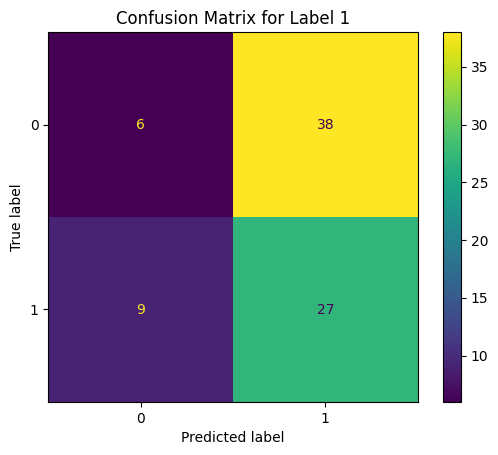

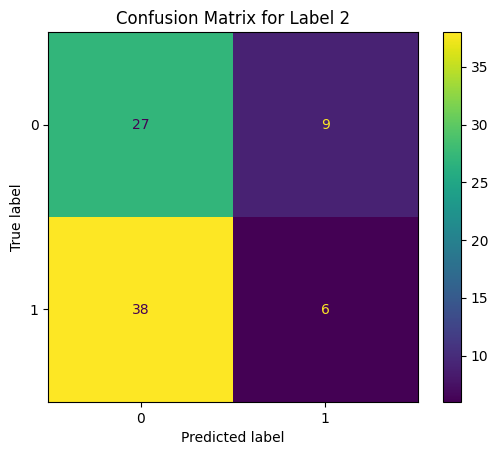

In [14]:
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    import matplotlib.pyplot as plt

    # Convert to numpy arrays
    y_test_np = y_test.numpy()
    predicted_np = predicted.numpy()
    
    # Compute confusion matrix for each label
    confusion_matrices = []
    for i in range(y_test_np.shape[1]):  # Iterate over each label
        cm = confusion_matrix(y_test_np[:, i], predicted_np[:, i])
        confusion_matrices.append(cm)
    
    # Display confusion matrices
    for i, cm in enumerate(confusion_matrices):
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot()
        plt.title(f'Confusion Matrix for Label {i+1}')
        plt.show()

In [15]:
### DEPRECATED ###

In [16]:

# # Örnek tahminler
# sample_data = pd.DataFrame({
#     'file_name': ['ProtoSubject.java','BasicAnnotationProcessor.java'], #1:enhancement, 2:enhancement
#     'full_repo_name': ['google/truth','google/auto']
# })

# # Kodlama işlemleri
# sample_data['file_name_encoded'] = le_class.transform(sample_data['file_name'])
# sample_data['full_repo_name_encoded'] = le_repo.transform(sample_data['full_repo_name'])

# # Özellikleri hazırlama
# X_sample = sample_data[['file_name_encoded', 'full_repo_name_encoded']]
# X_sample = torch.tensor(X_sample.to_numpy(), dtype=torch.float32)

# with torch.no_grad():
#     model.eval()
#     test_outputs = model(X_sample)
#     predicted = torch.sigmoid(test_outputs)  # Sigmoid fonksiyonu uygulanmalı
#     print( predicted)
#     predicted = (predicted > 0.5).float()  # 0.5'ten büyük olanlar 1, diğerleri 0
#     print("after ceiling")
#     print( predicted)